In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display


In [2]:
project_root = next(
    p for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "data" / "processed" / "btc_spy_daily.csv").exists()
)
PROCESSED_DIR = project_root / "data" / "processed"
RESULTS_DIR = project_root / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

ROLLING_WINDOWS = [63, 252]  # Approximately three months and one trading year


In [3]:
prices = pd.read_csv(
    PROCESSED_DIR / "btc_spy_daily.csv", index_col="date", parse_dates=True
).rename(columns={"price_btc": "BTC", "price_spy": "SPY"})[["BTC", "SPY"]]

assert prices.index.is_monotonic_increasing, "Prices must be sorted by date."
assert prices.index.is_unique, "Duplicate dates found."
assert np.isfinite(prices.to_numpy()).all(), "Missing or infinite prices found."
assert prices.gt(0).all().all(), "Prices must be positive."
assert all(isinstance(w, int) and w >= 2 for w in ROLLING_WINDOWS)
assert len(set(ROLLING_WINDOWS)) == len(ROLLING_WINDOWS), "Use distinct windows."
assert len(prices) > max(ROLLING_WINDOWS), "Insufficient observations for the windows."

returns = prices.pct_change(fill_method=None).iloc[1:]
assert returns.std().gt(0).all(), "Correlation requires variation in both assets."
period_label = f"{prices.index[0]:%Y-%m-%d} to {prices.index[-1]:%Y-%m-%d}"
print(f"Price period: {period_label} | Paired return observations: {len(returns):,}")
display(returns.head().style.format("{:.2%}"))


Price period: 2013-12-27 to 2026-11-12 | Paired return observations: 3,238


,BTC,SPY
date,,
2013-12-30 00:00:00,2.87%,-0.02%
2013-12-31 00:00:00,-0.28%,0.47%
2014-01-02 00:00:00,6.42%,-0.96%
2014-01-03 00:00:00,2.04%,-0.02%
2014-01-06 00:00:00,16.44%,-0.29%


In [4]:
correlation_matrix = returns.corr(method="pearson")
full_period_correlation = correlation_matrix.loc["BTC", "SPY"]
display(correlation_matrix.style.format("{:.3f}"))
print(f"Full-period BTC–SPY return correlation: {full_period_correlation:.3f}")


,BTC,SPY
BTC,1.000,0.222
SPY,0.222,1.000


Full-period BTC–SPY return correlation: 0.222


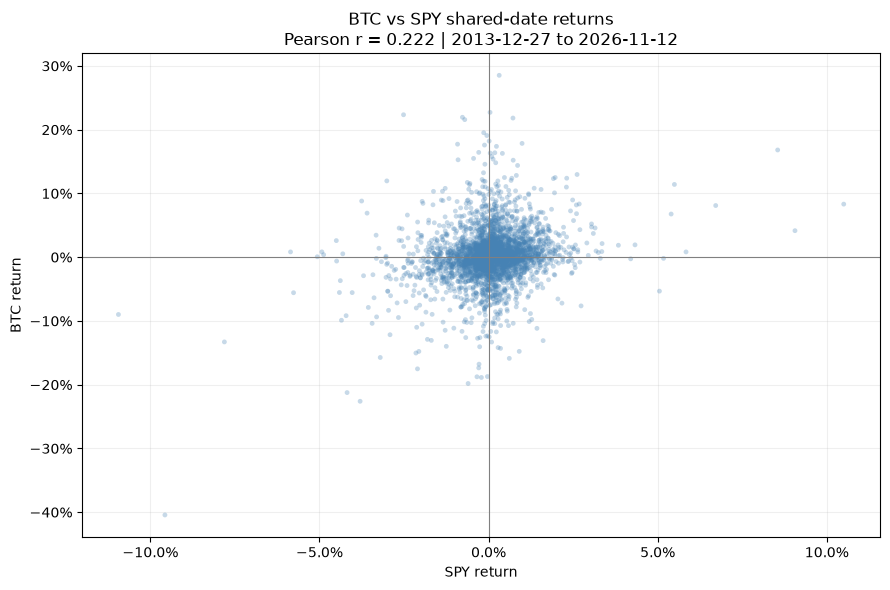

In [5]:
fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(returns["SPY"], returns["BTC"], s=12, alpha=0.3, color="steelblue", edgecolors="none")
ax.axhline(0, color="gray", linewidth=0.8)
ax.axvline(0, color="gray", linewidth=0.8)
ax.set_title(f"BTC vs SPY shared-date returns\nPearson r = {full_period_correlation:.3f} | {period_label}")
ax.set_xlabel("SPY return")
ax.set_ylabel("BTC return")
ax.xaxis.set_major_formatter(PercentFormatter(xmax=1))
ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))
ax.grid(alpha=0.2)
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(RESULTS_DIR / "correlation_scatter.png", dpi=300)
plt.show()


In [6]:
rolling_correlations = pd.DataFrame({
    f"{window}-return window": returns["BTC"].rolling(
        window=window, min_periods=window
    ).corr(returns["SPY"])
    for window in ROLLING_WINDOWS
})

for window, column in zip(ROLLING_WINDOWS, rolling_correlations.columns):
    additional_missing = rolling_correlations[column].iloc[window - 1:].isna().sum()
    if additional_missing:
        print(f"{column}: {additional_missing} undefined estimates after the initial window.")

display(rolling_correlations.tail().style.format("{:.3f}", na_rep="Undefined"))


,63-return window,252-return window
date,,
2026-11-06 00:00:00,0.530,0.478
2026-11-09 00:00:00,0.482,0.467
2026-11-10 00:00:00,0.485,0.468
2026-11-11 00:00:00,0.481,0.463
2026-11-12 00:00:00,0.481,0.465


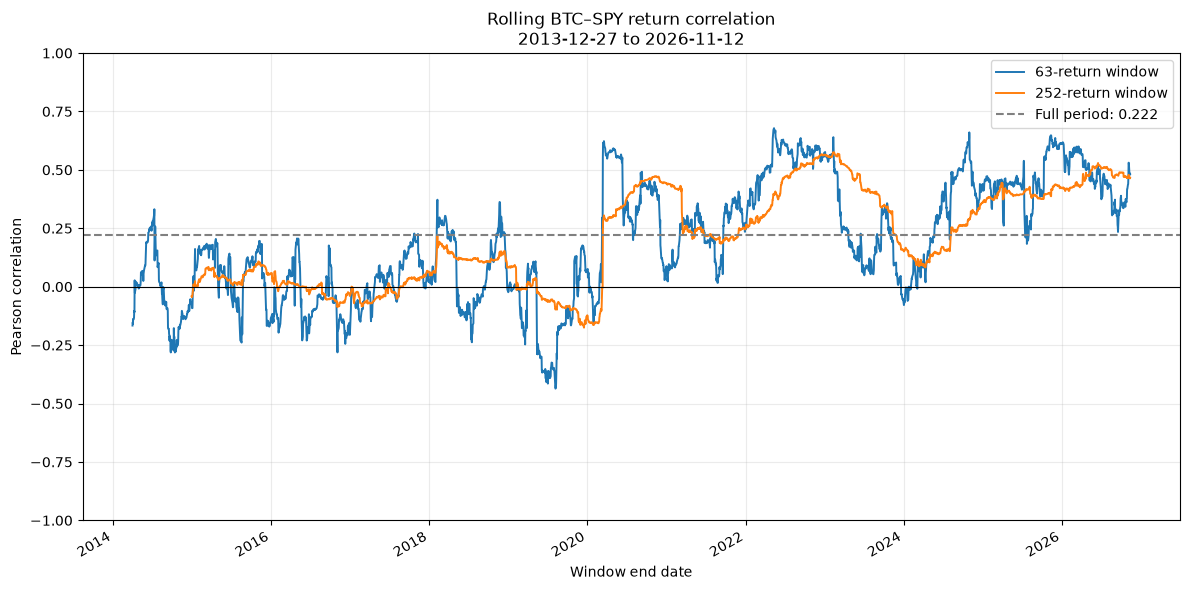

In [7]:
ax = rolling_correlations.plot(figsize=(12, 6), linewidth=1.4)
ax.axhline(0, color="black", linewidth=0.8)
ax.axhline(full_period_correlation, color="gray", linestyle="--", label=f"Full period: {full_period_correlation:.3f}")
ax.set_ylim(-1, 1)
ax.set_title(f"Rolling BTC–SPY return correlation\n{period_label}")
ax.set_xlabel("Window end date")
ax.set_ylabel("Pearson correlation")
ax.legend()
ax.grid(alpha=0.25)
fig = ax.get_figure()
fig.tight_layout()
fig.savefig(RESULTS_DIR / "rolling_correlations.png", dpi=300)
plt.show()


In [8]:
full_period_summary = pd.DataFrame({
    "Pearson correlation": [full_period_correlation],
    "Paired return observations": [len(returns)],
    "Price start": [prices.index[0].strftime("%Y-%m-%d")],
    "Price end": [prices.index[-1].strftime("%Y-%m-%d")],
}, index=["BTC vs SPY"])

rows = []
for column in rolling_correlations:
    valid = rolling_correlations[column].dropna()
    if valid.empty:
        raise ValueError(f"No defined correlations for {column}.")
    rows.append({
        "Window": column,
        "Latest available": valid.iloc[-1],
        "Latest date": valid.index[-1].strftime("%Y-%m-%d"),
        "Mean": valid.mean(),
        "Minimum": valid.min(),
        "Minimum date": valid.idxmin().strftime("%Y-%m-%d"),
        "Maximum": valid.max(),
        "Maximum date": valid.idxmax().strftime("%Y-%m-%d"),
        "Valid estimates": len(valid),
    })
rolling_summary = pd.DataFrame(rows).set_index("Window")
rolling_formats = {name: "{:.3f}" for name in ["Latest available", "Mean", "Minimum", "Maximum"]}
display(full_period_summary.style.format({"Pearson correlation": "{:.3f}"}))
display(rolling_summary.style.format(rolling_formats))


,Pearson correlation,Paired return observations,Price start,Price end
BTC vs SPY,0.222,3238,2013-12-27,2026-11-12


,Latest available,Latest date,Mean,Minimum,Minimum date,Maximum,Maximum date,Valid estimates
Window,,,,,,,,
63-return window,0.481,2026-11-12,0.192,-0.436,2019-08-06,0.678,2022-05-12,3176
252-return window,0.465,2026-11-12,0.210,-0.175,2019-12-16,0.575,2023-02-10,2987


In [9]:
correlation_matrix.to_csv(RESULTS_DIR / "correlation_matrix.csv", index_label="Asset")
full_period_summary.to_csv(RESULTS_DIR / "correlation_summary.csv", index_label="Pair")
rolling_correlations.to_csv(RESULTS_DIR / "rolling_correlations.csv", index_label="date")
rolling_summary.to_csv(RESULTS_DIR / "rolling_correlation_summary.csv")
assumptions = {
    "price_start": str(prices.index[0].date()),
    "price_end": str(prices.index[-1].date()),
    "paired_returns": len(returns),
    "method": "Pearson correlation of simple returns computed after date alignment",
    "rolling_windows_observations": ROLLING_WINDOWS,
    "min_periods": "Full window required; undefined estimates kept missing",
    "calendar": "Shared trading dates; BTC weekend movements enter the next shared-date return",
    "timestamp_limitation": "Source closing timestamps may differ",
}
(RESULTS_DIR / "correlation_assumptions.json").write_text(json.dumps(assumptions, indent=2), encoding="utf-8")
report = (
    '<!doctype html><html><head><meta charset="utf-8"><title>BTC vs SPY correlation</title>'
    '<style>body{font-family:system-ui;max-width:1150px;margin:40px auto;padding:0 20px;}'
    'table{border-collapse:collapse;}td,th{padding:9px;border-bottom:1px solid #ddd;text-align:right;}'
    'img{max-width:100%;}</style></head><body><h1>BTC vs SPY: return correlation</h1>'
    + full_period_summary.style.format({"Pearson correlation": "{:.3f}"}).to_html()
    + '<h2>Rolling correlation summary</h2>' + rolling_summary.style.format(rolling_formats).to_html()
    + '<p>Pearson correlation of simple returns on shared trading dates. '
    'BTC weekend movements enter the next shared-date return; source closing timestamps may differ. '
    'Rolling windows require the full number of observations. Overlapping estimates are not independent. '
    'Correlation is not causation, and a low full-period value does not guarantee protection during market losses.</p>'
    '<img src="correlation_scatter.png" alt="BTC versus SPY return scatter plot">'
    '<img src="rolling_correlations.png" alt="Rolling return correlations">'
    '</body></html>'
)
(RESULTS_DIR / "correlation_report.html").write_text(report, encoding="utf-8")
print(f"Saved four CSVs, assumptions JSON, two charts, and an HTML report to {RESULTS_DIR}")


Saved four CSVs, assumptions JSON, two charts, and an HTML report to /Users/nikolaskefalonitis/Desktop/All_folders/projects/quant/btcVSsp500/results
